In [ ]:
from pathlib import Path
import pandas as pd

PASTA = Path.cwd()

# Se o notebook estiver dentro de analise_dados,
# volta para a pasta principal do projeto.
if PASTA.name == "analise_dados":
    PASTA = PASTA.parent

obrigacoes = pd.read_csv(
    PASTA / "obrigacoes.csv",
    encoding="utf-8-sig"
)

dividas = pd.read_csv(
    PASTA / "dividas_reais.csv",
    encoding="utf-8-sig"
)

print("Dados carregados com sucesso!")

Dados carregados com sucesso!


In [ ]:
display(obrigacoes.head())
display(dividas.head())

,origem,nome,valor,vencimento,status
0,Conta Outubro,Cartão Neon,382.82,05/10/2026,Pendente
1,Conta Outubro,Cartão Atacadão,277.41,05/10/2026,Pendente
2,Conta Outubro,Cartão Bradesco,283.63,05/10/2026,Pendente
3,Conta Outubro,Cartão Dibs,279.04,05/10/2026,Pendente
4,Conta Outubro,Cartão Mais,357.43,05/10/2026,Pendente


,nome,tipo,saldo_devedor,parcela,juros_mensal,parcelas_restantes,status
0,Cartão Neon,Cartão,720.0,382.82,0.0,0,Em andamento
1,Cartão Atacadão,Cartão,237.0,277.41,0.0,0,Em andamento
2,Cartão Bradesco,Cartão,285.0,283.63,0.0,0,Em andamento
3,Cartão Dibs,Cartão,0.0,279.04,0.0,0,Em andamento
4,Cartão Mais,Cartão,358.0,357.43,0.0,0,Em andamento


In [ ]:
# Separar obrigações por status
pendentes = obrigacoes[
    obrigacoes["status"] == "Pendente"
]

planejadas = obrigacoes[
    obrigacoes["status"] == "Planejado"
]

# Calcular os totais
total_pendente = pendentes["valor"].sum()
total_planejado = planejadas["valor"].sum()

print("=== BOLSA MAGRA ===")
print(f"Obrigações pendentes: {len(pendentes)}")
print(f"Total pendente: R$ {total_pendente:,.2f}")
print(f"Obrigações planejadas: {len(planejadas)}")
print(f"Total planejado: R$ {total_planejado:,.2f}")

=== BOLSA MAGRA ===
Obrigações pendentes: 15
Total pendente: R$ 6,906.40
Obrigações planejadas: 1
Total planejado: R$ 830.00


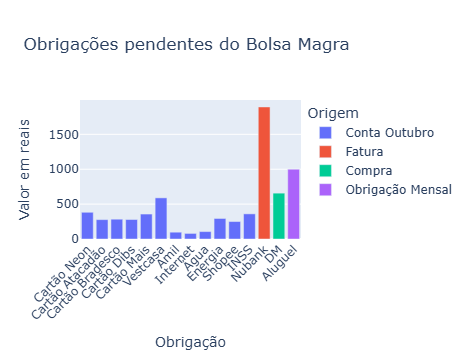

In [ ]:
import plotly.express as px

grafico = px.bar(
    pendentes,
    x="nome",
    y="valor",
    color="origem",
    title="Obrigações pendentes do Bolsa Magra",
    labels={
        "nome": "Obrigação",
        "valor": "Valor (R$)",
        "origem": "Origem"
    }
)

grafico.update_layout(
    xaxis_tickangle=-45,
    yaxis_title="Valor em reais"
)

grafico.show()

In [ ]:
# Agrupar as obrigações pendentes por origem
resumo = (
    pendentes
    .groupby("origem")["valor"]
    .sum()
    .sort_values(ascending=False)
)

display(resumo)

origem
Conta Outubro       3357.4
Fatura              1892.0
Obrigação Mensal    1000.0
Compra               657.0
Name: valor, dtype: float64

In [ ]:
# Valores de referência
receita_prevista = 14640.00

# Total de obrigações pendentes
despesas_pendentes = pendentes["valor"].sum()

# Saldo projetado
saldo_projetado = receita_prevista - despesas_pendentes

# Percentual comprometido
percentual_comprometido = (
    despesas_pendentes / receita_prevista
) * 100

print("=== PAINEL FINANCEIRO ===")
print(f"Receita prevista: R$ {receita_prevista:,.2f}")
print(f"Obrigações pendentes: R$ {despesas_pendentes:,.2f}")
print(f"Saldo projetado: R$ {saldo_projetado:,.2f}")
print(f"Comprometimento: {percentual_comprometido:.1f}%")

=== PAINEL FINANCEIRO ===
Receita prevista: R$ 14,640.00
Obrigações pendentes: R$ 6,906.40
Saldo projetado: R$ 7,733.60
Comprometimento: 47.2%


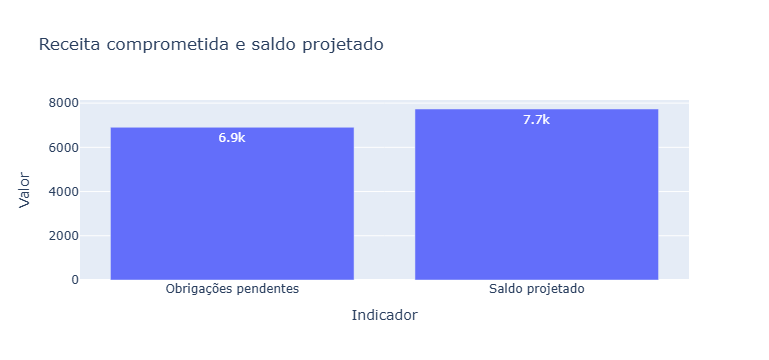

In [ ]:
import plotly.express as px

indicadores = pd.DataFrame({
    "Indicador": [
        "Obrigações pendentes",
        "Saldo projetado"
    ],
    "Valor": [
        despesas_pendentes,
        saldo_projetado
    ]
})

fig = px.bar(
    indicadores,
    x="Indicador",
    y="Valor",
    text_auto=".2s",
    title="Receita comprometida e saldo projetado"
)

fig.show()